# MVP — Análise de Dados e Boas Práticas
**Selic, inflação e câmbio no Brasil (séries do Banco Central, SGS)**

Aluno: Matheus Cecatto Paim

## 1. Problema e perguntas

### 1.1 Problema, relevância e unidade de observação
Selic, inflação e dólar mexem com as decisões de empresas, investidores e consumidores. Numa transportadora como a Paim, a inflação aumenta custos (combustível, manutenção, pneus, salários), o dólar pesa no diesel e nas peças importadas, e a Selic deixa o financiamento de um caminhão mais caro e aperta o fluxo de caixa. Olhar os três juntos ajuda a entender o cenário e a decidir melhor.

**Unidade de observação:** um mês. IPCA e Selic já são mensais. O dólar é diário e será resumido por mês (a forma de resumir é a decisão D1, seção 5.2). A volatilidade do dólar (H2) é calculada com os dados diários, antes de agregar.

### 1.2 Perguntas e objetivo analítico
- **H1:** a Selic e a inflação têm relação inversa, mas com atraso: depois de períodos de Selic mais alta, o IPCA tende a desacelerar. Vou testar defasagens de 0 a 24 meses. Câmbio, preços internacionais e choques de oferta também afetam a inflação, então a relação pode ser fraca.
- **H2:** a volatilidade do dólar é maior em períodos de instabilidade, como 2015 (crise política e fiscal), 2020 (pandemia) e 2022 (guerra na Ucrânia e juros internacionais). Vou comparar a volatilidade de cada ano com a dos demais.

**Objetivo analítico:** descritivo e exploratório. Quero ver como Selic, inflação e dólar se comportaram ao longo do tempo, achar períodos de maior instabilidade e investigar possíveis relações entre eles. Não há modelo de previsão neste trabalho.

## 2. Fonte e significado dos dados

### 2.1 Fonte
- Fonte: Banco Central do Brasil, Sistema Gerenciador de Séries Temporais (SGS) — https://api.bcb.gov.br
- Séries: IPCA mensal (433, % a.m.), Selic acumulada no mês (4390, % a.m.), dólar venda diário (1, R$/US$)
- Obtenção: ver `DATA_SNAPSHOT_DATE` na seção 3. Período: ver saída da seção 3.
- Condições de uso: dados públicos do Banco Central, obtidos pela API aberta do SGS sem chave de acesso; os termos de uso estão no portal de dados abertos do BCB (https://dadosabertos.bcb.gov.br). Snapshot do período de 01/2010 a 10/2026 guardado em `bcb_sgs_bruto.csv` no repositório do trabalho.

### 2.2 Dicionário
| Variável | Significado | Tipo | Unidade | Observação |
|---|---|---|---|---|
| data | data de referência | datetime | — | identificador temporal |
| serie | nome da série | texto | — | ipca_mensal, selic_acum_mes, dolar_venda_diario |
| valor | valor observado | float | % a.m. ou R$/US$ | ausência = NaN (sem código sentinela) |

**Sobre a Selic usada:** é a série 4390, Selic acumulada no mês (taxa efetiva, % a.m.), e não a Selic meta definida pelo Copom (série 432, % a.a.). Escolhi a acumulada por estar na mesma unidade do IPCA mensal. Limite: ela varia com o número de dias úteis do mês, então dois meses com a mesma meta podem ter valores diferentes.

## 3. Ambiente e carregamento

In [1]:
import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for pacote in ("pandas", "numpy", "matplotlib", "seaborn", "requests"):
    print(f"{pacote}: {version(pacote)}")

Python: 3.13.18
pandas: 3.0.5
numpy: 2.5.3
matplotlib: 3.11.2
seaborn: 0.13.2
requests: 2.34.2


In [2]:
import io
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt, seaborn as sns

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# URL do snapshot CSV no GitHub (raw). Preencher após subir o arquivo.
CSV_URL = "https://raw.githubusercontent.com/MatheusCPaim/MVP-Analise-BCB/refs/heads/main/bcb_sgs_bruto.csv"
DATA_SNAPSHOT_DATE = "2026-11-16"   # data em que o snapshot foi baixado
API = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.{c}/dados?formato=json&dataInicial={i}&dataFinal={f}"
SERIES = {"ipca_mensal": 433, "selic_acum_mes": 4390, "dolar_venda_diario": 1}

def baixar_sgs(codigo, ini, fim):
    r = requests.get(API.format(c=codigo, i=ini, f=fim), timeout=60)
    r.raise_for_status()
    d = pd.DataFrame(r.json())
    d["data"] = pd.to_datetime(d["data"], dayfirst=True)
    d["valor"] = pd.to_numeric(d["valor"], errors="coerce")
    return d

def carregar_bruto():
    if CSV_URL:
        d = pd.read_csv(CSV_URL, parse_dates=["data"])
        return d
    partes = [baixar_sgs(433, "01/01/2010", "31/10/2026").assign(serie="ipca_mensal"),
              baixar_sgs(4390, "01/01/2010", "31/10/2026").assign(serie="selic_acum_mes"),
              pd.concat([baixar_sgs(1, "01/01/2010", "31/12/2019"),
                         baixar_sgs(1, "01/01/2020", "31/10/2026")]).assign(serie="dolar_venda_diario")]
    return pd.concat(partes, ignore_index=True)

bruto = carregar_bruto()
df_origem = bruto.copy()   # visão de origem preservada (não é alterada)
print(bruto.shape)
bruto.groupby("serie")["data"].agg(["count", "min", "max"])

(4631, 3)


,count,min,max
serie,,,
dolar_venda_diario,4227,2010-01-04,2026-10-30
ipca_mensal,202,2010-01-01,2026-10-01
selic_acum_mes,202,2010-01-01,2026-10-01


## 4. Análise exploratória

### 4.1 Qualidade dos dados

In [3]:
print("Tipos:\n", bruto.dtypes, "\n")
print("Nulos por série:\n", bruto.groupby("serie")["valor"].apply(lambda s: s.isna().sum()), "\n")
print("Duplicatas (data, serie):", bruto.duplicated(["data", "serie"]).sum())
print("Valores <= 0 no dólar:", (bruto.query("serie=='dolar_venda_diario'")["valor"] <= 0).sum())
for nome, g in bruto.groupby("serie"):
    g = g.sort_values("data")
    print(f"{nome}: ordenada={g['data'].is_monotonic_increasing}, maior intervalo entre datas = {g['data'].diff().max().days} dias")

def extremos_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())
dol = bruto[bruto.serie == "dolar_venda_diario"].sort_values("data")
intervalos = dol["data"].diff().dt.days
print("\nIntervalos entre cotações do dólar (dias):", intervalos.value_counts().sort_index().to_dict())
print("Datas após intervalo de 5 dias:", dol.loc[intervalos == 5, "data"].dt.strftime("%d/%m/%Y").tolist())
print("\nExtremos (regra do IQR) por série:")
print(bruto.groupby("serie")["valor"].apply(extremos_iqr))

Tipos:
 data     datetime64[us]
valor           float64
serie               str
dtype: object 

Nulos por série:
 serie
dolar_venda_diario    0
ipca_mensal           0
selic_acum_mes        0
Name: valor, dtype: int64 

Duplicatas (data, serie): 0
Valores <= 0 no dólar: 0
dolar_venda_diario: ordenada=True, maior intervalo entre datas = 5 dias
ipca_mensal: ordenada=True, maior intervalo entre datas = 31 dias
selic_acum_mes: ordenada=True, maior intervalo entre datas = 31 dias

Intervalos entre cotações do dólar (dias): {1.0: 3274, 2.0: 75, 3.0: 809, 4.0: 48, 5.0: 20}
Datas após intervalo de 5 dias: ['17/02/2010', '09/03/2011', '25/04/2011', '22/02/2012', '13/02/2013', '05/03/2014', '22/04/2014', '18/02/2015', '10/02/2016', '01/03/2017', '14/02/2018', '06/03/2019', '26/02/2020', '17/02/2021', '02/03/2022', '22/02/2023', '14/02/2024', '05/03/2025', '22/04/2025', '18/02/2026']

Extremos (regra do IQR) por série:
serie
dolar_venda_diario    0
ipca_mensal           2
selic_acum_mes        0


**Diagnóstico de qualidade — interpretação**

**Qualidade geral:** a base tem boa qualidade estrutural: 0 nulos, 0 duplicatas e nenhum valor menor ou igual a zero no dólar. Pelo método do IQR há 2 valores extremos no IPCA e nenhum nas demais séries. Esses testes não garantem que todos os dados estejam corretos, então é importante considerar a origem e o contexto das observações.

**Intervalos de datas:** o maior intervalo na série diária do dólar é de 5 dias, e nas séries mensais é de 31 dias. Isso não é necessariamente um problema: há 20 intervalos de 5 dias no dólar, 17 deles em fevereiro ou março e 3 em abril, o que é compatível com feriados (Carnaval, Páscoa e Tiradentes), quando não há cotação publicada. Nas séries mensais, 31 dias é compatível com a frequência de divulgação. O importante é que essas lacunas correspondam ao calendário esperado e não a falhas de coleta.

**Extremos do IPCA:** os dois valores (mar/2022 e jul/2022) são mantidos, pois representam variações registradas na economia e não foram identificados como erros de coleta (decisão D2). Eles podem influenciar as estatísticas e as correlações, por isso são destacados na interpretação dos resultados.

### 4.2 Estatísticas descritivas

In [4]:
def resumo(s):
    return pd.Series({"min": s.min(), "max": s.max(), "mediana": s.median(),
                      "moda": s.round(2).mode().iloc[0], "media": s.mean(),
                      "desvio_padrao": s.std(), "nulos": s.isna().sum(), "n": s.count()})
tabela_desc = bruto.groupby("serie")["valor"].apply(resumo).unstack().round(4)
tabela_desc

,min,max,mediana,moda,media,desvio_padrao,nulos,n
serie,,,,,,,,
dolar_venda_diario,1.5345,6.2086,3.7858,2.03,3.7716,1.4106,0.0,4227.0
ipca_mensal,-0.6800,1.6200,0.4400,0.26,0.4659,0.3605,0.0,202.0
selic_acum_mes,0.1300,1.2800,0.8400,1.07,0.7934,0.2829,0.0,202.0


### 4.3 Figuras
Ver as figuras abaixo; seleção: série temporal de cada variável (H1/H2), volatilidade do dólar (H2) e correlação defasada Selic→IPCA (H1).

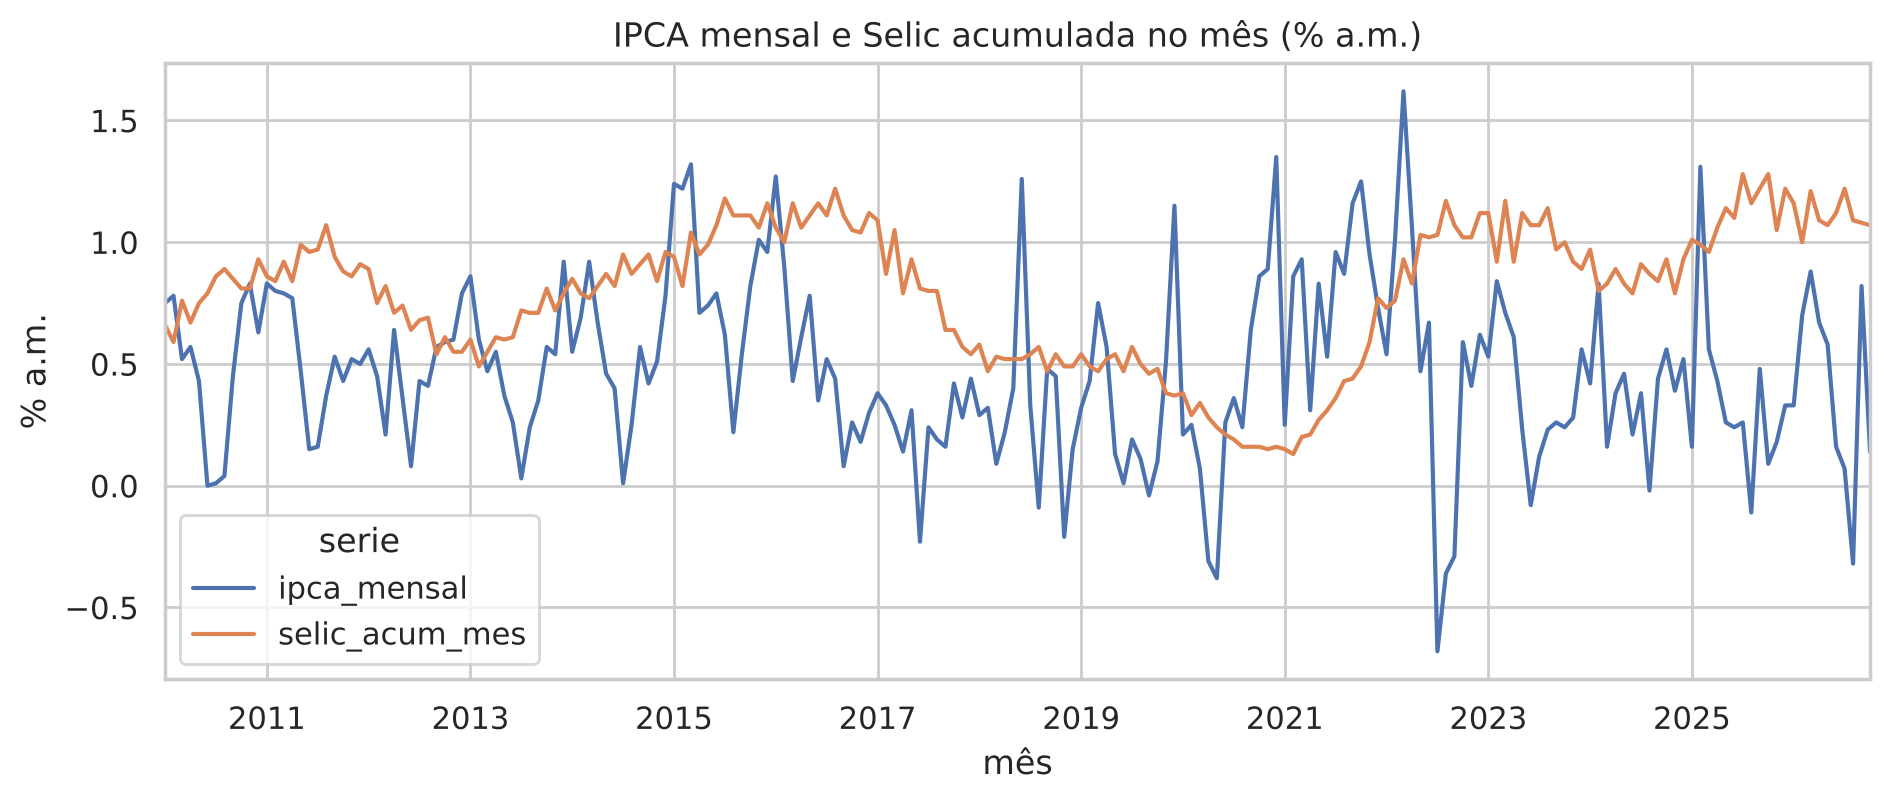

In [5]:
mensal = (bruto[bruto.serie != "dolar_venda_diario"]
          .pivot(index="data", columns="serie", values="valor").sort_index())
mensal.index = mensal.index.to_period("M").to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4))
mensal.plot(ax=ax)
ax.set_title("IPCA mensal e Selic acumulada no mês (% a.m.)"); ax.set_xlabel("mês"); ax.set_ylabel("% a.m.")
plt.show()

**Figura 1 — interpretação**

**Achado:** a Selic acumulada no mês (% a.m.) teve o menor valor da série em fevereiro de 2021 (0,13%). Entre 2021 e 2022 houve um aumento grande da Selic, e em 2025 ela chegou aos maiores valores da série (1,28% em julho e em outubro). O IPCA mensal passou de uma média de 0,80% em 2021 para 0,47% em 2022.

**Evidência:** Selic média de 0,36% em 2021 e 0,98% em 2022; Selic média de 1,12% em 2025; IPCA médio de 0,80% em 2021 e 0,47% em 2022.

**Relação com H1 e limite:** o comportamento entre 2021 e 2022 está de acordo com a hipótese de que o aumento dos juros pode contribuir para reduzir a inflação, mas não comprova relação de causa, pois outros fatores, como o dólar e os custos de produção, também influenciam os preços. A comparação usa médias anuais de duas séries apenas.

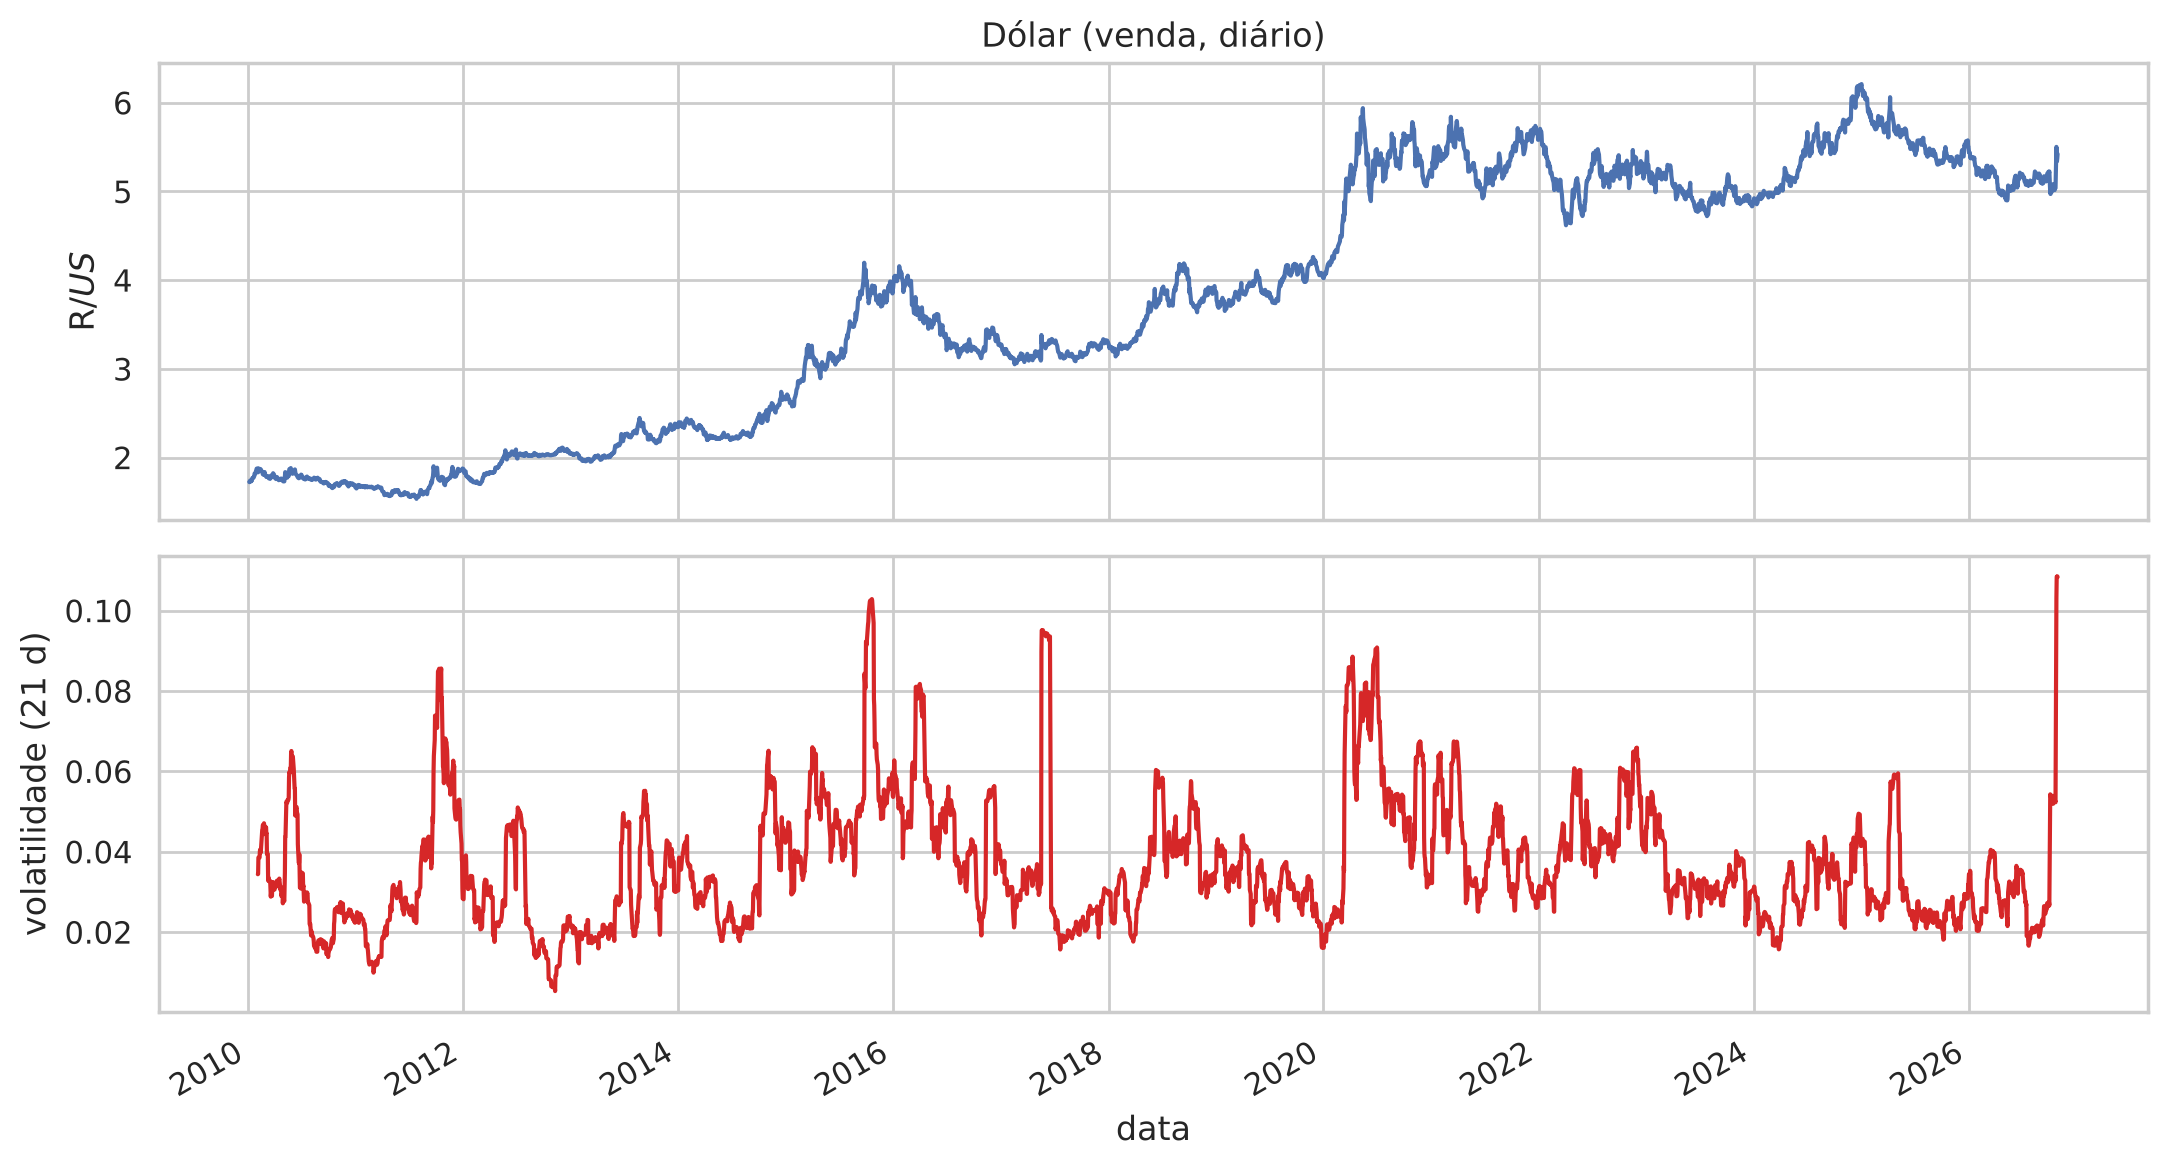

count    4206.0000
mean        0.0365
std         0.0155
min         0.0053
25%         0.0254
50%         0.0327
75%         0.0446
max         0.1085
Name: valor, dtype: float64
Dia(s) de maior volatilidade: {Timestamp('2026-10-29 00:00:00'): 0.1085, Timestamp('2026-10-27 00:00:00'): 0.1084, Timestamp('2026-10-28 00:00:00'): 0.1084}

Volatilidade anualizada por ano:
 data
2010    0.1116
2011    0.1395
2012    0.0996
2013    0.1096
2014    0.1228
2015    0.1915
2016    0.1690
2017    0.1274
2018    0.1366
2019    0.1107
2020    0.2027
2021    0.1473
2022    0.1608
2023    0.1177
2024    0.1109
2025    0.1032
2026    0.1489


In [6]:
d = (bruto[bruto.serie == "dolar_venda_diario"].set_index("data")["valor"].sort_index())
ret = np.log(d).diff().dropna()
vol = ret.rolling(21).std() * np.sqrt(21)   # janela de ~1 mês útil
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
d.plot(ax=axs[0]); axs[0].set_ylabel("R$/US$"); axs[0].set_title("Dólar (venda, diário)")
vol.plot(ax=axs[1], color="tab:red"); axs[1].set_ylabel("volatilidade (21 d)")
plt.tight_layout(); plt.show()
print(vol.describe().round(4))
print("Dia(s) de maior volatilidade:", vol.nlargest(3).round(4).to_dict())
vol_anual = (ret.groupby(ret.index.year).std() * np.sqrt(252)).round(4)
print("\nVolatilidade anualizada por ano:\n", vol_anual.to_string())

**Figura 2 — interpretação**

**Achado:** na volatilidade anualizada dos retornos log diários do dólar, 2015 (0,1915) e 2020 (0,2027) se destacam dos demais anos. 2022 (0,1608) ficou abaixo de 2016 (0,1690), então não foi tão diferente de outros anos. 2026 (0,1489, ano incompleto, só até outubro) e 2016 também ficaram acima da média dos demais anos, de cerca de 0,125. O pico da volatilidade em janela de 21 dias ocorre em 27 a 29/out/2026 (0,1085), muito ligado a um único dia: o dólar passou de R$ 5,0377 em 23/10 para R$ 5,5007 em 26/10.

**Evidência:** volatilidade anual de 0,1915 (2015), 0,2027 (2020), 0,1608 (2022), 0,1690 (2016) e 0,1489 (2026); média dos demais anos de cerca de 0,125; pico da janela de 21 dias de 0,1085 em 29/10/2026.

**Relação com H2 e limite:** os resultados são compatíveis com a H2, mas ela precisa ser ampliada, pois a volatilidade não ficou concentrada apenas em 2015, 2020 e 2022. Limites: o pico do fim da série depende de um único dia e de um período incompleto, não dá para tratá-lo como tendência; a janela de 21 dias não está anualizada e não é comparável aos valores anuais; os números descrevem oscilação, não explicam a causa.

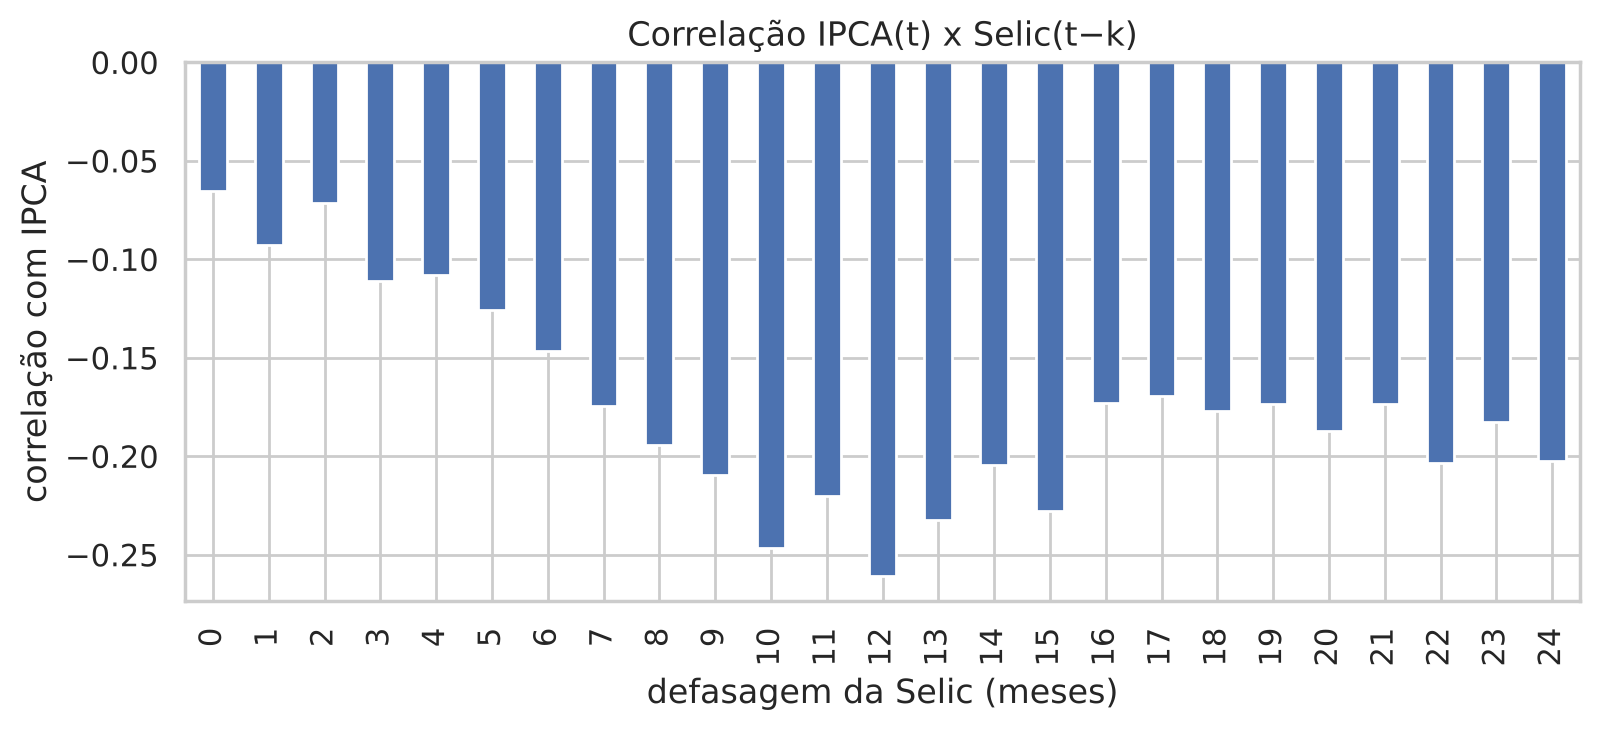

Maior |correlação|: k = 12 valor = -0.261


In [7]:
base = mensal.dropna()
atrasos = range(0, 25)
corr = pd.Series({k: base["ipca_mensal"].corr(base["selic_acum_mes"].shift(k)) for k in atrasos})
fig, ax = plt.subplots(figsize=(9, 3.5))
corr.plot.bar(ax=ax); ax.set_xlabel("defasagem da Selic (meses)"); ax.set_ylabel("correlação com IPCA")
ax.set_title("Correlação IPCA(t) x Selic(t−k)"); plt.show()
print("Maior |correlação|: k =", corr.abs().idxmax(), "valor =", round(corr[corr.abs().idxmax()], 3))

**Figura 3 — interpretação**

**Achado:** na correlação entre o IPCA mensal e a Selic acumulada defasada em k meses (k de 0 a 24), todas as correlações são negativas e, em geral, aumentam em módulo até a defasagem de 12 meses, onde ocorre o maior valor absoluto. A correlação é fraca a moderada, e a relação aparece em torno de 12 meses, não necessariamente exatamente nessa defasagem.

**Evidência:** correlação de −0,065 em k = 0, −0,147 em k = 6, −0,246 em k = 10 e −0,261 em k = 12 (a maior em módulo); em k = 11 e k = 13 os valores são −0,220 e −0,232. A autocorrelação de 1 mês da Selic é 0,95, o que indica que ela muda gradualmente.

**Relação com H1 e limite:** os resultados apoiam a direção esperada em H1, uma relação inversa e com atraso, mas não bastam para confirmá-la por completo. Como a Selic é muito persistente, os valores vizinhos de k são parecidos e fica difícil apontar um único ponto de maior relação. Uma correlação de −0,26 é limitada e não demonstra que as mudanças na Selic explicam as mudanças no IPCA; foram comparadas 25 defasagens e a maior foi escolhida, e as séries são analisadas em nível, sem controlar outros fatores.

## 5. Pré-processamento e decisões

### 5.1 Plano e vazamento
**Divisão treino/teste:** não se aplica diretamente, porque o trabalho é descritivo e não constrói um modelo de previsão. O objetivo é analisar o comportamento das séries, suas variações e as relações entre elas. Sem etapa de treinamento ou de avaliação de previsões, separar os dados não acrescentaria valor.

**Se houvesse modelo de previsão:** não se deveria sortear linhas aleatoriamente, pois isso misturaria informações do passado e do futuro e geraria uma avaliação artificialmente otimista. Em séries temporais, o adequado seria treinar com períodos mais antigos e testar em períodos posteriores.

**Vazamento nas transformações:** a média mensal e o retorno logarítmico são operações aplicadas às observações e não estimam parâmetros globais, como a média ou o desvio-padrão da amostra inteira; por isso não representam vazamento de parâmetros aprendidos. Em um modelo preditivo, qualquer transformação que estimasse parâmetros com os dados teria de ser ajustada só no conjunto de treino e depois aplicada ao teste.

### 5.2 D1 — Como agregar o dólar diário em mês

In [8]:
g = d.groupby(d.index.to_period("M"))
agreg = pd.DataFrame({"media_mes": g.mean(), "fim_mes": g.last()})
agreg["amplitude_pct"] = (g.max() - g.min()) / g.mean() * 100
agreg["ret_media"] = np.log(agreg.media_mes).diff()
agreg["ret_fim"] = np.log(agreg.fim_mes).diff()
comp = pd.DataFrame({
    "desvio_padrao_retorno_mensal": [agreg.ret_media.std(), agreg.ret_fim.std()],
    "autocorr_lag1": [agreg.ret_media.autocorr(1), agreg.ret_fim.autocorr(1)],
    "maior_alta": [agreg.ret_media.max(), agreg.ret_fim.max()],
}, index=["média do mês", "fim do mês"]).round(4)
print("Linhas antes (diário):", len(d), "| depois (mensal):", len(agreg), "| meses com nulo:", agreg.isna().sum().to_dict())
comp

Linhas antes (diário): 4227 | depois (mensal): 202 | meses com nulo: {'media_mes': 0, 'fim_mes': 0, 'amplitude_pct': 0, 'ret_media': 1, 'ret_fim': 1}


,desvio_padrao_retorno_mensal,autocorr_lag1,maior_alta
média do mês,0.0337,0.2594,0.1178
fim do mês,0.0425,-0.0506,0.1556


**D1 — Agregação do dólar em mês**

**Necessidade e evidência:** o dólar é cotado por dia útil (4.227 observações), enquanto IPCA e Selic são mensais (202 observações cada, tabela da seção 3). Para que as três séries tenham a mesma unidade de observação e possam ser comparadas (H1), é preciso transformar o dólar em uma observação por mês.

**Alternativas:** (a) média das cotações do mês; (b) cotação do último dia útil do mês; (c) manter o dólar diário, o que deixaria as séries em frequências diferentes.

**Escolha e justificativa:** média mensal, porque representa o comportamento do dólar ao longo de todo o mês, sem depender de um único dia. Na comparação da célula acima, o desvio-padrão do retorno mensal foi 0,0337 com a média e 0,0425 com o fim do mês; parte dessa diferença vem da própria suavização da média. A volatilidade da H2 foi calculada com os dados diários, então esta escolha afeta apenas a série mensal usada com IPCA e Selic.

**Verificação:** 4.227 linhas diárias viraram 202 meses; nenhum mês ficou sem valor (as colunas `media_mes`, `fim_mes` e `amplitude_pct` não têm nulos; o único nulo está no primeiro retorno, pois não há mês anterior).

**Limitação:** a autocorrelação de lag 1 do retorno com a média (0,2594, contra −0,0506 no fim do mês) pode vir, em parte, da suavização e não do comportamento do dólar. A média também pode esconder movimentos bruscos de dias específicos, como a alta de 26/10/2026. Seria útil repetir a análise com outras formas de agregação.

### 5.3 D2 — Extremos e recorte do período

In [9]:
n_ext = int(vol.gt(vol.quantile(0.99)).sum())
print("Observações de volatilidade acima do p99:", n_ext, "de", len(vol))
print("Antes/depois do recorte: série IPCA/Selic", base.shape, "linhas;",
      "meses sem par IPCA+Selic:", int(mensal.isna().any(axis=1).sum()))

Observações de volatilidade acima do p99: 43 de 4226
Antes/depois do recorte: série IPCA/Selic (202, 2) linhas; meses sem par IPCA+Selic: 0


**D2 — Tratamento dos valores extremos**

**Necessidade e evidência:** verificar se movimentos muito fora do padrão poderiam influenciar média, dispersão e correlação. Na seção 4.1, o IPCA tem 2 valores extremos pela regra do IQR (mar/2022 = 1,62 e jul/2022 = −0,68), e na Figura 2 há um movimento diário do dólar de cerca de 8,8% em 26/10/2026 (R$ 5,0377 em 23/10 para R$ 5,5007 em 26/10).

**Alternativas:** (a) manter todos os valores; (b) remover os extremos; (c) limitá-los (winsorização).

**Escolha e justificativa:** manter todos, por serem observações válidas e não erros de registro. Remover ou limitar esses pontos esconderia justamente os episódios de maior inflação e instabilidade cambial que o trabalho quer analisar.

**Verificação:** os extremos do IPCA fazem parte de sequências coerentes: 0,54 (jan), 1,01 (fev), 1,62 (mar), 1,06 (abr) e 0,47 (mai); depois 0,67 (jun), −0,68 (jul), −0,36 (ago) e −0,29 (set). A página do IBGE de julho/2022 informa −0,68% (divulgado em 09/08/2022), com queda de combustíveis e de energia elétrica residencial. As observações de volatilidade acima do percentil 99 (43 de 4.226, cerca de 1%) não servem como evidência de anomalia, pois esse número decorre da própria definição do percentil.

**Limitação:** um valor distante dos demais pode influenciar a média, a volatilidade e a correlação mesmo sendo válido. E, se algum extremo fosse erro de coleta, mantê-lo sem correção distorceria a análise.

### 5.4 D3 — Nível ou retorno do dólar

In [10]:
niv_mudanca = d.groupby(d.index.year).mean()
print("Média anual do dólar (nível):\n", niv_mudanca.round(2).to_string())
print("\nMédia anual do retorno log diário:\n", ret.groupby(ret.index.year).mean().round(5).to_string())
pct = d.pct_change().dropna()
print("\nRetorno log x variação percentual diária:")
print("correlação:", round(ret.corr(pct), 5), "| maior diferença absoluta:", round((ret - pct).abs().max(), 5), "| desvio-padrão log:", round(ret.std(), 5), "| desvio-padrão pct:", round(pct.std(), 5))

Média anual do dólar (nível):
 data
2010    1.76
2011    1.67
2012    1.95
2013    2.16
2014    2.35
2015    3.34
2016    3.48
2017    3.19
2018    3.66
2019    3.95
2020    5.16
2021    5.40
2022    5.17
2023    5.00
2024    5.39
2025    5.59
2026    5.15

Média anual do retorno log diário:
 data
2010   -0.00014
2011    0.00047
2012    0.00034
2013    0.00054
2014    0.00050
2015    0.00154
2016   -0.00072
2017    0.00006
2018    0.00063
2019    0.00016
2020    0.00101
2021    0.00028
2022   -0.00027
2023   -0.00030
2024    0.00097
2025   -0.00047
2026   -0.00007

Retorno log x variação percentual diária:
correlação: 0.99991 | maior diferença absoluta: 0.00398 | desvio-padrão log: 0.00876 | desvio-padrão pct: 0.00877


**D3 — Nível ou retorno do dólar**

**Necessidade e evidência:** o nível do dólar mostra o preço da moeda, não o tamanho das oscilações. A média anual do nível passou de R$ 1,76 em 2010 para R$ 5,59 em 2025 (célula acima), o que não significa que a volatilidade tenha crescido na mesma proporção. Para medir volatilidade (H2) é preciso observar as variações.

**Alternativas:** (a) usar o nível; (b) usar a variação percentual diária; (c) usar o retorno logarítmico diário.

**Escolha e justificativa:** retorno logarítmico diário, porque mostra a variação proporcional de um dia para o outro e permite comparar períodos com níveis de câmbio diferentes. A variação percentual também seria válida, e o retorno log tem propriedades úteis em análises financeiras. O nível é mantido apenas para acompanhar a evolução da cotação.

**Verificação:** a média anual dos retornos log diários ficou sempre próxima de zero, entre −0,0007 e +0,0015, enquanto o nível subiu ao longo dos anos. Os retornos são variações que podem ser positivas ou negativas e acabam se compensando na média. A comparação entre retorno log e variação percentual está na saída da célula acima.

**Limitação:** o retorno logarítmico é menos intuitivo para quem não conhece a medida e exige explicação adicional na apresentação dos resultados.

### 5.5 Estado final dos dados

In [11]:
final = mensal.join(agreg.set_index(agreg.index.to_timestamp())[["media_mes", "fim_mes", "amplitude_pct"]], how="left")
print("Dimensões origem:", df_origem.shape, "| final:", final.shape)
print("Nulos finais:\n", final.isna().sum())
print("Índice único e ordenado:", final.index.is_unique and final.index.is_monotonic_increasing)
final.head()

Dimensões origem: (4631, 3) | final: (202, 5)
Nulos finais:
 ipca_mensal       0
selic_acum_mes    0
media_mes         0
fim_mes           0
amplitude_pct     0
dtype: int64
Índice único e ordenado: True


,ipca_mensal,selic_acum_mes,media_mes,fim_mes,amplitude_pct
data,,,,,
2010-01-01,0.75,0.66,1.779820,1.8748,8.545808
2010-02-01,0.78,0.59,1.841633,1.8110,3.947583
2010-03-01,0.52,0.76,1.785843,1.7810,3.326159
2010-04-01,0.57,0.67,1.756570,1.7306,2.846456
2010-05-01,0.43,0.75,1.813190,1.8167,8.250650


## 6. Respostas e conclusão

| Pergunta | Resposta | Evidência | O que permanece incerto |
|---|---|---|---|
| **H1** — relação inversa e defasada entre Selic e IPCA | Apoiada em parte | Selic média de 0,36% em 2021 e 0,98% em 2022; IPCA médio de 0,80% para 0,47% nos mesmos anos; correlação de −0,26 em torno de 12 meses (Figuras 1 e 3) | A relação é de intensidade fraca a moderada e não permite afirmar que a Selic causou a redução da inflação |
| **H2** — maior volatilidade do dólar em períodos de instabilidade | Apoiada em parte | Volatilidade anualizada de 0,1915 (2015) e 0,2027 (2020); 2022 com 0,1608, abaixo de 2016 (0,1690); 2026 com 0,1489, ano incompleto (Figura 2) | A volatilidade elevada não ficou restrita a 2015, 2020 e 2022; o resultado de 2026 é parcial |

### Limitações
- A Selic usada é a acumulada no mês (taxa efetiva), e não a meta definida pelo Copom, e depende do número de dias úteis do mês.
- Outros fatores econômicos não foram incluídos, como câmbio, preços internacionais e decisões fiscais.
- A correlação foi calculada com as séries em nível, o que exige cautela na interpretação.
- O pico de volatilidade no fim de 2026 pode ter sido influenciado por um movimento diário excepcional (26/10/2026).
- Os resultados mostram associações e padrões, mas não explicam sozinhos os motivos de cada movimento.

### Próximos passos
- Incluir outras variáveis econômicas, como atividade econômica, câmbio e preços de commodities.
- Testar as correlações com variações e retornos em vez de séries em nível.
- Comparar os resultados com outras formas de agregação do dólar e avaliar o impacto dos valores extremos.
- Desenvolver um modelo preditivo com separação temporal entre treino e teste, avaliando se os padrões também aparecem em períodos posteriores.

## 7. Checklist de entrega
| # | Item | Localização |
|---|---|---|
| 1 | Problema, unidade, perguntas, objetivo | 1.1, 1.2 |
| 2 | Origem, período, condições, dicionário | 2.1, 2.2, 3 |
| 3 | Dimensões, tipos, estatísticas | 3, 4.2 |
| 4 | Ausências, duplicidades, extremos | 4.1 |
| 5 | Distribuições e relações | 4.3 |
| 6 | Interpretações com evidências | 4.3 |
| 7 | D1–D3 e comparação | 5.2–5.4 |
| 8 | Transformações e antes/depois | 5.2–5.5 |
| 9 | Vazamento / não aplicabilidade | 5.1 |
| 10 | Respostas, limitações, próximos passos | 6 |
| 11 | Template, dados, dependências, execução | 3, README |
| 12 | Versão e permissões conferidas | Conferir antes do envio: commit dentro do prazo e link do Colab com permissão de leitura e escrita |

## Referências
- Banco Central do Brasil. Sistema Gerenciador de Séries Temporais (SGS), API de dados abertos: séries 433 (IPCA mensal), 4390 (Selic acumulada no mês) e 1 (dólar, venda). https://api.bcb.gov.br/dados/serie/bcdata.sgs.{código}/dados. Portal de dados abertos: https://dadosabertos.bcb.gov.br
- Banco Central do Brasil. Boletins PTAX (cotações do dólar). https://ptax.bcb.gov.br/ptax_internet/consultaBoletim.do
- IBGE. IPCA foi de 1,62% em março (2022). https://agenciadenoticias.ibge.gov.br/agencia-sala-de-imprensa/2013-agencia-de-noticias/releases/33436-ipca-foi-de-1-62-em-marco
- IBGE. IPCA tem queda de 0,68% em julho (2022). https://agenciadenoticias.ibge.gov.br/agencia-sala-de-imprensa/2013-agencia-de-noticias/releases/34579-ipca-tem-queda-de-0-68-em-julho
- Bibliotecas: pandas, NumPy, Matplotlib, seaborn e requests (versões na seção 3).
- Repositório com o snapshot dos dados e este notebook: https://github.com/MatheusCPaim/MVP-Analise-BCB

## Declaração de uso de IA
Usei o Claude (Anthropic) como apoio técnico: escrita e execução do código, gráficos, tabelas de estatísticas, comparações das decisões D1 a D3, revisão dos textos e conferência de números com a saída do notebook. Usei também o ChatGPT (OpenAI) como apoio na redação de rascunhos de interpretação e na busca de fontes. As interpretações, decisões e conclusões foram revisadas e adotadas por mim, e respondi às perguntas que orientaram cada seção. A conferência dos valores nas páginas do IBGE e nos boletins PTAX foi feita com apoio de ferramentas de IA. Sou responsável por todo o conteúdo entregue.